## Node2Vec:

---

In [2]:
import pickle

with open('../01-Dataset/graph_network.pkl', 'rb') as file:
    G = pickle.load(file)

In [3]:
from node2vec import Node2Vec

node2vec = Node2Vec(
    G, 
    seed=42, 
    dimensions=64, 
    walk_length=30, 
    num_walks=200, 
    workers=4 # n_jobs
)

d:\GitHub\Repositories\Behavioral Homophily Network\behavioral-homophily-network\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Computing transition probabilities: 100%|██████████| 150/150 [00:00<00:00, 178.39it/s]


In [4]:
model = node2vec.fit(
    window=10,
    min_count=1,
    batch_words=4
)

In [5]:
embeddings = model.wv
print(f"Successfully embedded {len(embeddings.key_to_index)} nodes into 64-dimensional space.")
print("150 nodes, each represented by 64 dimensional vector")

Successfully embedded 150 nodes into 64-dimensional space.
150 nodes, each represented by 64 dimensional vector


---

## PCA:

In [6]:
print(type(embeddings))

<class 'gensim.models.keyedvectors.KeyedVectors'>


In [7]:
import numpy as np

# Converting from strings to keys
node_id = list(model.wv.key_to_index.keys())

# Sorting
node_id.sort(key=int)
vectors_64d = np.array([model.wv[str(node)] for node in node_id])

In [8]:
print(f"Class type: {type(vectors_64d)}")
print(f"Shape: {vectors_64d.shape}")


Class type: <class 'numpy.ndarray'>
Shape: (150, 64)


In [9]:
display(vectors_64d)


array([[ 6.0435653e-02, -2.0113175e-01,  2.5445923e-01, ...,
         8.0448680e-02,  6.7275837e-03,  2.4302275e-01],
       [ 8.2179122e-02, -1.9202612e-01,  2.7882648e-01, ...,
         2.2046991e-02,  1.1462356e-01,  5.3497396e-02],
       [ 4.2177744e-02, -2.6150373e-01,  6.5381870e-02, ...,
         1.7177812e-03, -9.9166214e-02,  1.8319745e-01],
       ...,
       [-5.4519948e-02, -1.2044533e-01,  2.8684869e-01, ...,
         1.3638277e-02,  4.1040856e-02,  1.0140985e-01],
       [ 1.0220854e-01, -2.0581709e-01,  3.0492914e-01, ...,
        -1.4300146e-02, -4.8004095e-02,  3.3758017e-01],
       [-1.0089006e-01, -2.0702198e-01,  4.0785345e-01, ...,
         1.5702317e-04,  1.2010630e-02,  6.4647794e-02]], dtype=float32)

In [10]:
# Loading the pyshcological profile labels:

node_labels = np.load('../01-Dataset/node_labels.npy')
display(node_labels)

array([2, 1, 2, 1, 0, 1, 0, 0, 2, 1, 1, 1, 1, 1, 0, 2, 2, 2, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 2, 1, 0, 2, 0, 1, 2, 1, 2,
       2, 2, 1, 0, 0, 2, 2, 2, 0, 2, 0, 0, 1, 2, 2, 1, 2, 1, 0, 2, 2, 0,
       1, 0, 1, 1, 0, 2, 2, 2, 0, 2, 0, 1, 0, 1, 2, 1, 1, 1, 0, 2, 1, 0,
       2, 0, 1, 0, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 0, 0, 0, 2, 1, 0, 0,
       0, 2, 2, 0, 2, 0, 0, 1, 1, 1, 0, 2, 2, 1, 2, 1, 0, 0, 0, 2, 0, 1,
       1, 1, 2, 0, 2, 1, 1, 2, 0, 0, 2, 2, 2, 2, 1, 1, 2, 1], dtype=int64)

In [11]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

In [12]:
vectors_2d = pca.fit_transform(vectors_64d)
print(f"Shape: {vectors_2d.shape}")

Shape: (150, 2)


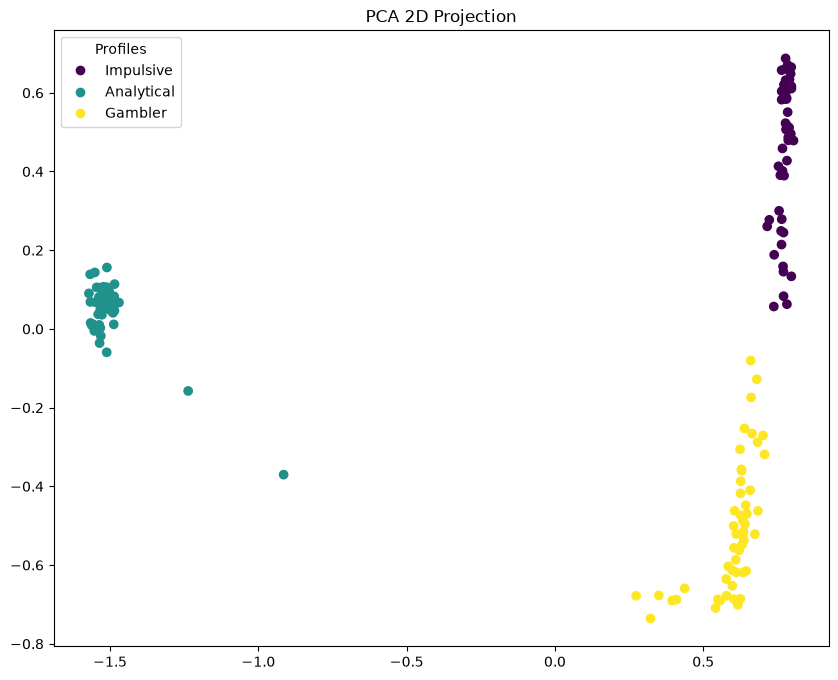

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

scatter = plt.scatter(x=vectors_2d[:, 0], y=vectors_2d[:, 1], c=node_labels)

profiles = ['Impulsive', 'Analytical', 'Gambler']
plt.legend(handles=scatter.legend_elements()[0], labels=profiles, title='Profiles')
plt.title('PCA 2D Projection')

plt.show()

---

### t-SNE:

In [14]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    max_iter=1000, 
    random_state=42
)

In [15]:
vectors_tsne = tsne.fit_transform(vectors_64d)

In [1]:
plt.figure(figsize=(10, 8))

scatter = plt.scatterplot(
    x=vectors_tsne[:, 0],
    y=vectors_tsne[:, 1],
    hue=node_labels,
    palette='vlag',
)

plt.show()

NameError: name 'plt' is not defined